# 03 — Expériences & Benchmark
Config-driven : modifier `EXPERIMENTS_TO_RUN` pour choisir quelles expériences lancer.

Progression **pyramidale** — chaque expérience ajoute un seul levier :

| Exp | Image | Crop | Meta | OOF texte | OOF image | Rich | Extra | Levier ajouté |
|-----|-------|------|------|-----------|-----------|------|-------|---------------|
| E1_text_only | — | — | — | — | — | — | — | *baseline* |
| E2_dino_lin_meta_logreg | DINOv2 gelé | non | LogReg | OUI | OUI (5-fold) | — | — | + image |
| E3_dino_lin_crop_meta_logreg | DINOv2 gelé | **oui** | LogReg | OUI | OUI (5-fold) | — | — | + crop |
| E4_dino_lin_crop_meta_mlp | DINOv2 gelé | oui | **MLP** | OUI | OUI (5-fold) | **OUI** | **OUI** | + MLP + rich + extra |
| E5_dino_ft_meta_mlp | DINOv2 **FT** | non | MLP | OUI | *(in-sample)* | OUI | OUI | + FT image |

**Pourquoi OOF image pour lin mais pas FT ?**  
Lin gelé : entraînement rapide → 5 folds OK.  
FT (fine-tune 2 blocs) : ~30 min/run → 5 × 2h30 trop coûteux → in-sample acceptable.

**Extra** = `has_desc` + `zoom_ratio` | **Rich** = entropy, margin, max\_conf, accord texte/image

In [ ]:
import os, sys, pickle
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

try:
    import lightgbm as lgb
    LGBM_OK = True
    print('LightGBM disponible')
except ImportError:
    LGBM_OK = False
    print('LightGBM absent — pip install lightgbm | E5 utilisera MLP ameliore')

LightGBM disponible


In [ ]:
BASE         = r'C:/Users/veyss/Nouveau dossier/nov25_alt1_mle_rakuten'
CLEAN_PROC   = os.path.join(BASE, 'data', 'processed_clean')
CLEAN_MODELS = os.path.join(BASE, 'models', 'clean')

y_train = np.load(os.path.join(CLEAN_PROC, 'y_train.npy'))
y_val   = np.load(os.path.join(CLEAN_PROC, 'y_val.npy'))
y_test  = np.load(os.path.join(CLEAN_PROC, 'y_test.npy'))

with open(os.path.join(CLEAN_PROC, 'label_encoder.pkl'), 'rb') as f:
    le = pickle.load(f)
class_names = [str(c) for c in le.inverse_transform(range(27))]

X_ctfidf = {s: np.load(os.path.join(CLEAN_PROC, f'X_ctfidf_{s}.npy')) for s in ['train','val','test']}
X_extra  = {s: np.load(os.path.join(CLEAN_PROC, f'X_extra_{s}.npy'))  for s in ['train','val','test']}

P_text = {
    'oof'  : np.load(os.path.join(CLEAN_PROC, 'P_text_oof_train.npy')),
    'val'  : np.load(os.path.join(CLEAN_PROC, 'P_text_val.npy')),
    'test' : np.load(os.path.join(CLEAN_PROC, 'P_text_test.npy')),
}
# DINOv2 linéaire no-crop (OOF propre 5-fold)
P_lin = {
    'oof'  : np.load(os.path.join(CLEAN_PROC, 'P_dino_lin_oof_train.npy')),
    'val'  : np.load(os.path.join(CLEAN_PROC, 'P_dino_lin_val.npy')),
    'test' : np.load(os.path.join(CLEAN_PROC, 'P_dino_lin_test.npy')),
}
# DINOv2 linéaire crop (OOF propre 5-fold)
P_lin_crop = {
    'oof'  : np.load(os.path.join(CLEAN_PROC, 'P_dino_lin_crop_oof_train.npy')),
    'val'  : np.load(os.path.join(CLEAN_PROC, 'P_dino_lin_crop_val.npy')),
    'test' : np.load(os.path.join(CLEAN_PROC, 'P_dino_lin_crop_test.npy')),
}
# DINOv2 fine-tuné (OOF propre si dispo, sinon in-sample fallback)
_ft_oof_path   = os.path.join(CLEAN_PROC, 'P_dino_ft_oof_train.npy')
_ft_train_path = os.path.join(CLEAN_PROC, 'P_dino_ft_train.npy')
_ft_oof_exists = os.path.exists(_ft_oof_path)
P_ft = {
    'oof'  : np.load(_ft_oof_path)   if _ft_oof_exists else np.load(_ft_train_path),
    'train': np.load(_ft_train_path),
    'val'  : np.load(os.path.join(CLEAN_PROC, 'P_dino_ft_val.npy')),
    'test' : np.load(os.path.join(CLEAN_PROC, 'P_dino_ft_test.npy')),
}
_ft_oof_label = 'OOF propre' if _ft_oof_exists else 'in-sample (TRAIN_FT_OOF=False)'
print(f'FT meta-train → {_ft_oof_label}')

print('Probas chargées :')
for name, split, proba in [
    ('text_oof',      y_train, P_text['oof']),
    ('text_val',      y_val,   P_text['val']),
    ('lin_val',       y_val,   P_lin['val']),
    ('lin_crop_val',  y_val,   P_lin_crop['val']),
    ('ft_val',        y_val,   P_ft['val']),
]:
    print(f'  {name:<16} F1={f1_score(split, proba.argmax(1), average="macro"):.4f}')
print(f'X_extra shape : {X_extra["train"].shape}  (has_desc, zoom_ratio)')

## ⚙️ CONFIG — modifier ici pour choisir les expériences

In [ ]:
# ╔══════════════════════════════════════════════════════════════╗
# ║   EXPERIMENT REGISTRY                                        ║
# ╚══════════════════════════════════════════════════════════════╝
#   img_source  : None | 'lin' | 'lin_crop' | 'ft'
#   crop        : True → images croppees (split/), False → no-crop
#   extra_feats : True → has_desc + zoom_ratio
#   rich_feats  : True → entropy, margin, max_conf, accord
#   meta        : None | 'logreg' | 'mlp' | 'lgbm'

EXPERIMENT_REGISTRY = {

    # E1 ── Baseline texte seul ────────────────────────────────────────
    'E1_text_only': {
        'description' : 'Baseline : TF-IDF + c-TF-IDF + e5-large → LogReg',
        'fusion'      : 'text_only',
        'img_source'  : None,    'crop': False,
        'meta'        : None,    'oof' : False,
        'rich_feats'  : False,   'extra_feats': False,
    },

    # E2 ── + image (DINOv2 gelé no-crop) ─────────────────────────────
    'E2_dino_lin_meta_logreg': {
        'description' : '+ Image : DINOv2 gelé no-crop OOF + texte OOF → meta-LogReg',
        'fusion'      : 'meta',
        'img_source'  : 'lin',   'crop': False,
        'meta'        : 'logreg','oof' : True,
        'rich_feats'  : False,   'extra_feats': False,
    },

    # E3 ── + crop (images recadrées) ─────────────────────────────────
    'E3_dino_lin_crop_meta_logreg': {
        'description' : '+ Crop : DINOv2 gelé crop OOF + texte OOF → meta-LogReg',
        'fusion'      : 'meta',
        'img_source'  : 'lin_crop', 'crop': True,
        'meta'        : 'logreg',   'oof' : True,
        'rich_feats'  : False,      'extra_feats': False,
    },

    # E4 ── + MLP meta + rich features + extra ────────────────────────
    'E4_dino_lin_crop_meta_mlp': {
        'description' : '+ MLP meta + rich + extra : DINOv2 gelé crop OOF → meta-MLP',
        'fusion'      : 'meta',
        'img_source'  : 'lin_crop', 'crop': True,
        'meta'        : 'mlp',      'oof' : True,
        'rich_feats'  : True,       'extra_feats': True,
    },

    # E5 ── + FT image (DINOv2 fine-tuné) ─────────────────────────────
    'E5_dino_ft_meta_mlp': {
        'description' : '+ FT : DINOv2 fine-tune no-crop (in-sample) → meta-MLP',
        'fusion'      : 'meta',
        'img_source'  : 'ft',   'crop': False,
        'meta'        : 'mlp',  'oof' : True,
        'rich_feats'  : True,   'extra_feats': True,
    },

}

EXPERIMENTS_TO_RUN = [
    'E1_text_only',
    'E2_dino_lin_meta_logreg',
    'E3_dino_lin_crop_meta_logreg',
    'E4_dino_lin_crop_meta_mlp',
    'E5_dino_ft_meta_mlp',
]

print(f'{len(EXPERIMENTS_TO_RUN)} experiences (pyramide) :')
for i, name in enumerate(EXPERIMENTS_TO_RUN):
    cfg = EXPERIMENT_REGISTRY[name]
    levier = ['baseline', '+ image', '+ crop', '+ MLP/rich/extra', '+ FT'][i]
    print(f'  {name:<35} [{levier}]  img={cfg["img_source"] or "—":<8} crop={cfg["crop"]}  extra={cfg["extra_feats"]}')

5 experiences (pyramide) :
  E1_text_only                        [baseline]  img=—        crop=False  extra=False
  E2_dino_lin_meta_logreg             [+ image]  img=lin      crop=False  extra=False
  E3_dino_lin_crop_meta_logreg        [+ crop]  img=lin_crop crop=True  extra=False
  E4_dino_lin_crop_meta_mlp           [+ MLP/rich/extra]  img=lin_crop crop=True  extra=True
  E5_dino_ft_meta_mlp                 [+ FT]  img=ft       crop=False  extra=True


In [ ]:
# ── Feature engineering pour le meta-classifieur ─────────────────────
def entropy(P):
    P = np.clip(P, 1e-10, 1.0)
    return -(P * np.log(P)).sum(axis=1, keepdims=True).astype('float32')

def margin(P):
    s = np.sort(P, axis=1)
    return (s[:, -1] - s[:, -2]).reshape(-1, 1).astype('float32')

def build_meta_features(P_txt, P_img, ctfidf, extra=None, rich=True):
    """
    Base (81) : P_txt(27) + P_img(27) + ctfidf(27)
    rich (+7)  : entropy x2, margin x2, max_conf x2, accord(1)
    extra (+2) : has_desc, zoom_ratio
    """
    feats = [P_txt, P_img, ctfidf]
    if rich:
        feats += [
            entropy(P_txt), entropy(P_img),
            margin(P_txt),  margin(P_img),
            P_txt.max(axis=1, keepdims=True),
            P_img.max(axis=1, keepdims=True),
            (P_txt.argmax(1) == P_img.argmax(1)).astype('float32').reshape(-1, 1),
        ]
    if extra is not None:
        feats.append(extra.astype('float32'))
    return np.hstack(feats).astype('float32')

print('Helpers definis')

Helpers definis


In [ ]:
def run_experiment(name, cfg):
    src   = cfg['img_source']
    rich  = cfg['rich_feats']
    extra = cfg['extra_feats']

    # ── Probas image selon img_source ────────────────────────────────
    if src == 'lin':
        pi_tr, pi_val, pi_test = P_lin['oof'],      P_lin['val'],      P_lin['test']
    elif src == 'lin_crop':
        pi_tr, pi_val, pi_test = P_lin_crop['oof'], P_lin_crop['val'], P_lin_crop['test']
    elif src == 'ft':
        # OOF propre si TRAIN_FT_OOF=True, sinon in-sample (déjà résolu dans P_ft['oof'])
        pi_tr, pi_val, pi_test = P_ft['oof'],       P_ft['val'],       P_ft['test']
    else:
        pi_tr = pi_val = pi_test = None

    # ── Extra features (has_desc + zoom_ratio) ───────────────────────
    xtr  = X_extra['train'] if extra else None
    xval = X_extra['val']   if extra else None
    xte  = X_extra['test']  if extra else None

    # ── text_only ────────────────────────────────────────────────────
    if cfg['fusion'] == 'text_only':
        pv = P_text['val'].argmax(1)
        pt = P_text['test'].argmax(1)

    # ── meta stacking ─────────────────────────────────────────────────
    elif cfg['fusion'] == 'meta':
        ckpt = os.path.join(CLEAN_MODELS, f'meta_{name}.pkl')

        Xm_tr  = build_meta_features(P_text['oof'], pi_tr,    X_ctfidf['train'], xtr,  rich)
        Xm_val = build_meta_features(P_text['val'], pi_val,   X_ctfidf['val'],   xval, rich)
        Xm_te  = build_meta_features(P_text['test'],pi_test,  X_ctfidf['test'],  xte,  rich)
        n_feats = Xm_tr.shape[1]

        if os.path.exists(ckpt):
            with open(ckpt, 'rb') as f: meta = pickle.load(f)
            print(f'  meta chargé depuis cache ({n_feats} features)')
        else:
            print(f'  {n_feats} features meta | crop={cfg["crop"]} extra={extra} rich={rich}')
            meta_type = cfg['meta']
            if meta_type == 'lgbm' and LGBM_OK:
                print('  Entraînement meta-LightGBM...')
                meta = lgb.LGBMClassifier(
                    n_estimators=1000, learning_rate=0.05, max_depth=6,
                    num_leaves=63, min_child_samples=20,
                    subsample=0.8, colsample_bytree=0.8,
                    class_weight='balanced',
                    random_state=42, n_jobs=-1, verbose=-1)
                meta.fit(Xm_tr, y_train,
                         eval_set=[(Xm_val, y_val)],
                         callbacks=[lgb.early_stopping(80, verbose=False),
                                    lgb.log_evaluation(100)])
            elif meta_type == 'mlp':
                print('  Entraînement meta-MLP (256-128-64)...')
                meta = MLPClassifier(
                    hidden_layer_sizes=(256, 128, 64), activation='relu',
                    max_iter=600, early_stopping=True, validation_fraction=0.1,
                    learning_rate_init=3e-4, n_iter_no_change=20, random_state=42)
                meta.fit(Xm_tr, y_train)
            else:  # logreg
                print('  Entraînement meta-LogReg...')
                meta = LogisticRegression(C=2.0, max_iter=500, solver='saga', n_jobs=-1)
                meta.fit(Xm_tr, y_train)
            with open(ckpt, 'wb') as f: pickle.dump(meta, f)

        pv = meta.predict(Xm_val)
        pt = meta.predict(Xm_te)

    val_f1  = round(f1_score(y_val,  pv, average='macro'),    4)
    test_f1 = round(f1_score(y_test, pt, average='macro'),    4)
    test_fw = round(f1_score(y_test, pt, average='weighted'), 4)
    test_ac = round(accuracy_score(y_test, pt),               4)
    return dict(name=name, description=cfg['description'],
                F1_val=val_f1, F1_test=test_f1, Acc_test=test_ac, F1w_test=test_fw,
                _pv=pv, _pt=pt)

print('run_experiment défini')

## ▶ Lancement des expériences

In [ ]:
results = []
for exp_name in EXPERIMENTS_TO_RUN:
    cfg = EXPERIMENT_REGISTRY[exp_name]
    print(f'\n{"="*65}')
    print(f'[{exp_name}]')
    print(f'{cfg["description"]}')
    res = run_experiment(exp_name, cfg)
    results.append(res)
    print(f'  => val F1={res["F1_val"]:.4f} | test F1={res["F1_test"]:.4f}')


[E1_text_only]
Baseline : TF-IDF + c-TF-IDF + e5-large → LogReg
  => val F1=0.8340 | test F1=0.8343

[E2_dino_lin_meta_logreg]
+ Image : DINOv2 gelé no-crop OOF + texte OOF → meta-LogReg
  meta charge depuis cache (81 features)
  => val F1=0.8584 | test F1=0.8541

[E3_dino_lin_crop_meta_logreg]
+ Crop : DINOv2 gelé crop OOF + texte OOF → meta-LogReg
  81 features meta | crop=True extra=False rich=False
  Entrainement meta-LogReg...
  => val F1=0.8589 | test F1=0.8539

[E4_dino_lin_crop_meta_mlp]
+ MLP meta + rich + extra : DINOv2 gelé crop OOF → meta-MLP
  90 features meta | crop=True extra=True rich=True
  Entrainement meta-MLP (256-128-64)...
  => val F1=0.8451 | test F1=0.8447

[E5_dino_ft_meta_mlp]
+ FT : DINOv2 fine-tune no-crop (in-sample) → meta-MLP
  90 features meta | crop=False extra=True rich=True
  Entrainement meta-MLP (256-128-64)...
  => val F1=0.7346 | test F1=0.7330


## 📊 Benchmark

In [ ]:
df_bench = pd.DataFrame(
    [{k: v for k, v in r.items() if not k.startswith('_')} for r in results]
).sort_values('F1_test', ascending=False).reset_index(drop=True)

print('\n' + '='*78)
print('BENCHMARK CLEAN — 5 EXPERIENCES')
print('='*78)
print(df_bench[['name', 'F1_val', 'F1_test', 'Acc_test', 'F1w_test']].to_string(index=True))
print('='*78)
best = df_bench.iloc[0]
baseline = df_bench.loc[df_bench['name'] == 'E1_text_only', 'F1_test'].values
prev_best = 0.8550
print(f"\nMeilleur : {best['name']}  F1={best['F1_test']:.4f}")
if len(baseline) > 0:
    print(f"  vs baseline text-only : {baseline[0]:.4f}  (+{best['F1_test']-baseline[0]:+.4f})")
print(f"  vs meilleur precedent  : {prev_best:.4f}  ({'+' if best['F1_test']>prev_best else ''}{best['F1_test']-prev_best:.4f})")

# Combien battent 0.855
above = df_bench[df_bench['F1_test'] > prev_best]
print(f"\n{len(above)}/5 experiences battent le precedent record de {prev_best}")
if len(above) > 0:
    print(above[['name', 'F1_test']].to_string(index=False))


BENCHMARK CLEAN — 5 EXPERIENCES
                           name  F1_val  F1_test  Acc_test  F1w_test
0       E2_dino_lin_meta_logreg  0.8584   0.8541    0.8607    0.8599
1  E3_dino_lin_crop_meta_logreg  0.8589   0.8539    0.8605    0.8597
2     E4_dino_lin_crop_meta_mlp  0.8451   0.8447    0.8533    0.8521
3                  E1_text_only  0.8340   0.8343    0.8430    0.8416
4           E5_dino_ft_meta_mlp  0.7346   0.7330    0.7528    0.7516

Meilleur : E2_dino_lin_meta_logreg  F1=0.8541
  vs baseline text-only : 0.8343  (++0.0198)
  vs meilleur precedent  : 0.8550  (-0.0009)

0/5 experiences battent le precedent record de 0.855


In [ ]:
bench_path = os.path.join(CLEAN_MODELS, 'benchmark_clean.csv')
df_bench.drop(columns=[c for c in df_bench.columns if c.startswith('_')], errors='ignore')\
        .to_csv(bench_path, index=False)
print(f'Benchmark sauvegarde : {bench_path}')

Benchmark sauvegarde : C:/Users/veyss/Nouveau dossier/nov25_alt1_mle_rakuten\models\clean\benchmark_clean.csv


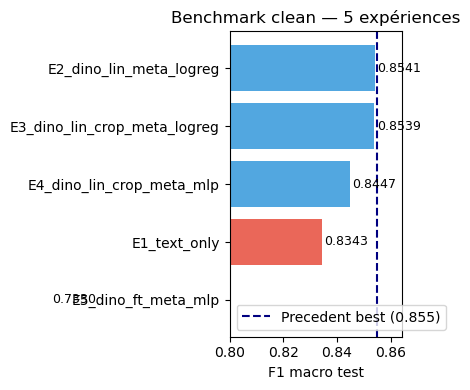

In [ ]:
# ── Graphique comparaison ─────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4))
colors = ['#2ECC71' if f > 0.8550 else '#3498DB' if f > 0.84 else '#E74C3C'
          for f in df_bench['F1_test']]
bars = ax.barh(df_bench['name'][::-1], df_bench['F1_test'][::-1], color=colors[::-1], alpha=0.85)
ax.axvline(0.8550, color='navy', linestyle='--', linewidth=1.5, label='Precedent best (0.855)')
ax.set_xlabel('F1 macro test')
ax.set_title('Benchmark clean — 5 expériences', fontsize=12)
ax.legend()
for bar, val in zip(bars, df_bench['F1_test'][::-1]):
    ax.text(val + 0.001, bar.get_y() + bar.get_height()/2, f'{val:.4f}',
            va='center', fontsize=9)
ax.set_xlim(0.80, max(df_bench['F1_test']) + 0.01)
plt.tight_layout()
plt.savefig(os.path.join(CLEAN_MODELS, 'benchmark_clean.png'), dpi=120)
plt.show()

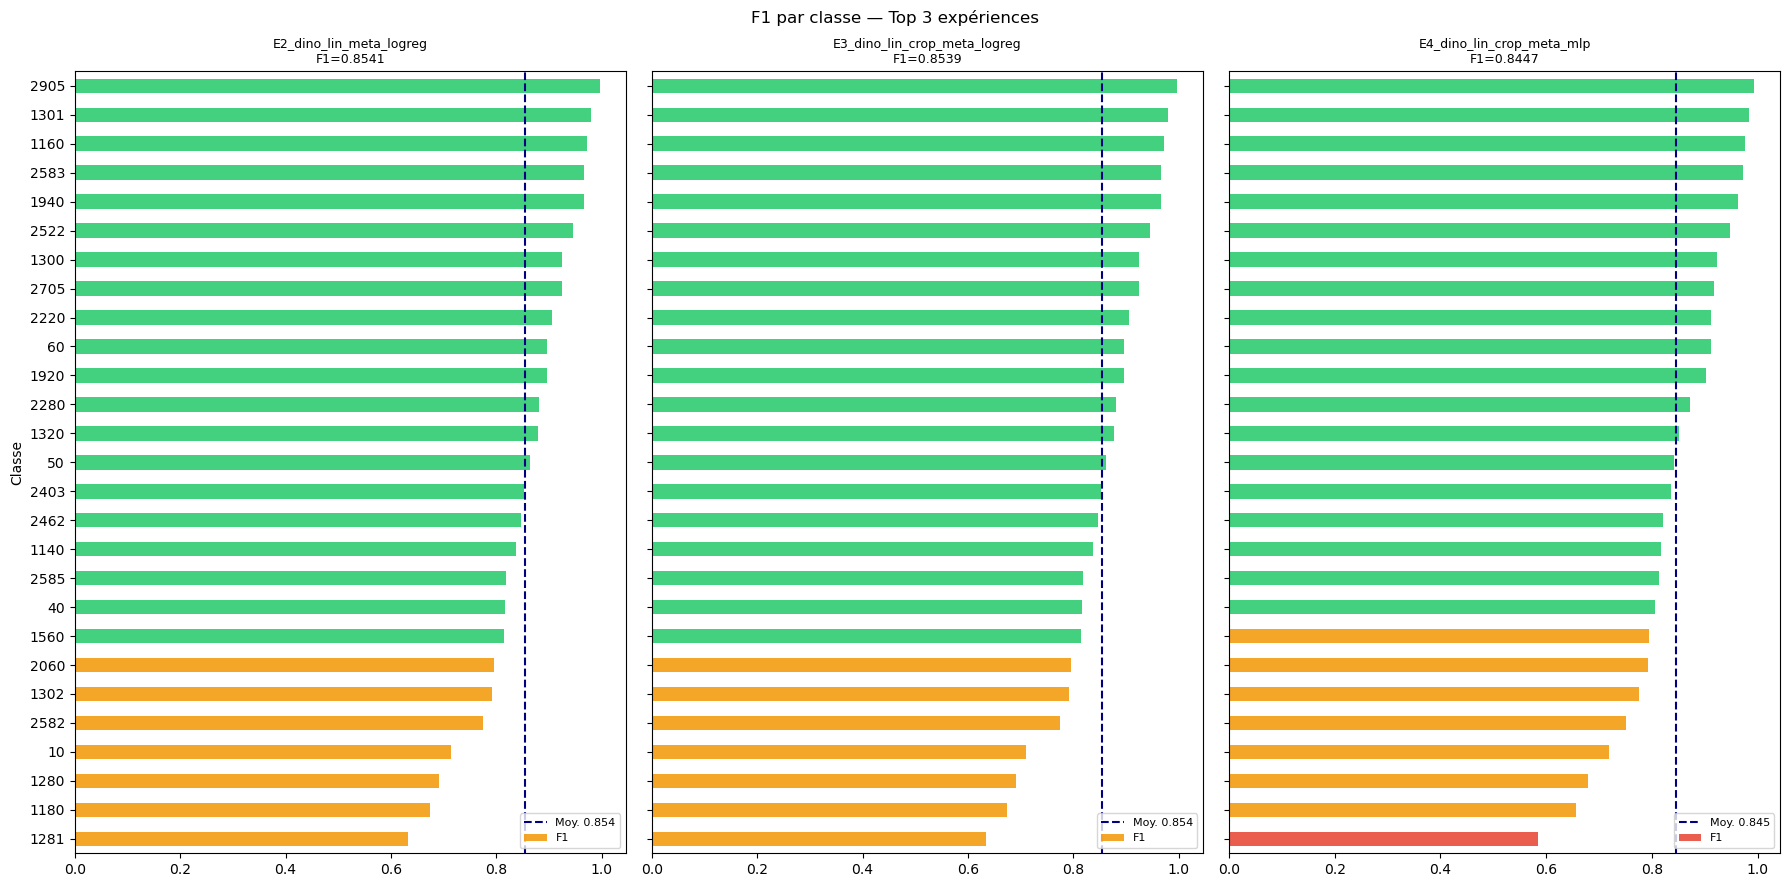

In [ ]:
# ── F1 par classe : 3 meilleures experiences ─────────────────────────
top3 = df_bench.head(3)
fig, axes = plt.subplots(1, 3, figsize=(18, 9), sharey=True)

for ax, (_, row) in zip(axes, top3.iterrows()):
    res_r = next(r for r in results if r['name'] == row['name'])
    f1_cls = f1_score(y_test, res_r['_pt'], average=None)
    df_f1  = pd.DataFrame({'Classe': class_names, 'F1': f1_cls}).set_index('Classe').sort_values('F1')
    colors = ['#E74C3C' if v<0.6 else '#F39C12' if v<0.8 else '#2ECC71' for v in df_f1['F1']]
    df_f1['F1'].plot(kind='barh', ax=ax, color=colors, alpha=0.9)
    ax.axvline(df_f1['F1'].mean(), color='navy', linestyle='--',
               label=f"Moy. {df_f1['F1'].mean():.3f}")
    ax.set_title(f"{row['name']}\nF1={row['F1_test']:.4f}", fontsize=9)
    ax.legend(fontsize=8)

plt.suptitle('F1 par classe — Top 3 expériences', fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(CLEAN_MODELS, 'f1_per_class_top3.png'), dpi=120)
plt.show()